# 1. Introduction

This notebook focuses on the **tabular data component** of the system. It uses customer social media profiles and transaction records to develop a machine learning model that predicts the product category a customer is likely to purchase.

The main tasks covered in this notebook include:

- Cleaning and preprocessing the two datasets.
- Merging customer social media and transaction data.
- Performing exploratory data analysis (EDA).
- Engineering relevant features for prediction.
- Training, tuning, and evaluating classification models.
- Preparing and saving the final product recommendation model.

The resulting model will serve as the product prediction component of the wider system, which also incorporates facial recognition and voice verification.

## 2. Libraries and Dependencies

Before beginning the data preprocessing process, we need to import the Python libraries that will support our analysis.

Libraries provide pre-built functions and tools that make it easier to manipulate datasets, perform numerical operations, analyze data, and create visualizations.

In this project, we will primarily use **Pandas** for data manipulation and analysis and **NumPy** for numerical computations. As we progress to exploratory data analysis, we will introduce additional visualization libraries where necessary.

The purpose of this section is to prepare our working environment before loading and processing the datasets.

In [90]:
# Import libraries for data manipulation and numerical operations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.metrics import log_loss
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from scipy.stats import randint
from scipy.stats import loguniform
import joblib



## 3. Loading the Datasets

Our project involves two data sources: customer social media profiles and customer transaction records.

Before performing any cleaning or transformation, we need to load both datasets into our Python environment.

The social media dataset contains information about customers' engagement and interests across different social media platforms. The transaction dataset contains information about customers' previous purchases, including purchase amounts, dates, product categories, and customer ratings.

Loading these datasets into Pandas DataFrames will allow us to inspect, clean, analyze, and eventually combine them to create a dataset suitable for product category prediction.

**Objective:**
- Load both CSV files into Pandas DataFrames.
- Ensure that both datasets are accessible for further processing.
- Preserve the original data before making any modifications.

In [2]:
# Load the original datasets

social = pd.read_csv("../data/customer_social_profiles.csv")

transactions = pd.read_csv("../data/customer_transactions.csv")
print("Both social and Customer transaction loaded successfully")

Both social and Customer transaction loaded successfully


In [3]:
print("Social Media Profiles Shape:", social.shape)

print("Customer Transactions Shape:", transactions.shape)

Social Media Profiles Shape: (155, 5)
Customer Transactions Shape: (150, 6)


The inspection confirms that both datasets were successfully loaded into Pandas DataFrames.

The customer social media dataset contains 155 observations and 5 variables, while the customer transactions dataset contains 150 observations and 6 variables.

The difference in the number of observations indicates that the two datasets do not necessarily contain the same number of records. This makes it important to investigate their customer identifiers and relationships before deciding on an appropriate merging strategy.

Both datasets will be retained in their original form throughout the preprocessing process.

In [4]:
# Display the first five records of the social media dataset

social.head()

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [5]:
# Display the first five records of the transactions dataset

transactions.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [6]:
# Display column names for both datasets

print("Social Media Dataset Columns:")
print(social.columns.tolist())

print("\nTransactions Dataset Columns:")
print(transactions.columns.tolist())

Social Media Dataset Columns:
['customer_id_new', 'social_media_platform', 'engagement_score', 'purchase_interest_score', 'review_sentiment']

Transactions Dataset Columns:
['customer_id_legacy', 'transaction_id', 'purchase_amount', 'purchase_date', 'product_category', 'customer_rating']


In [7]:
# Inspect the data types of both datasets

print("Social Media Dataset Data Types:")
print(social.dtypes)

print("\nTransactions Dataset Data Types:")
print(transactions.dtypes)

Social Media Dataset Data Types:
customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str
dtype: object

Transactions Dataset Data Types:
customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date             str
product_category          str
customer_rating       float64
dtype: object


In [8]:
# Inspect the overall structure of both datasets

print("Social media dataset information")
social.info()

print("\nCustomer transaction dataset information")
transactions.info()

Social media dataset information
<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    str    
 1   social_media_platform    155 non-null    str    
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 6.2 KB

Customer transaction dataset information
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    str    
 4   prod

In [9]:
social.describe()



,engagement_score,purchase_interest_score
count,155.000000,155.000000
mean,75.606452,3.152903
std,14.568021,1.142867
min,50.000000,1.000000
25%,63.500000,2.350000
50%,77.000000,3.200000
75%,87.500000,4.100000
max,99.000000,5.000000


In [10]:
transactions.describe()

,customer_id_legacy,transaction_id,purchase_amount,customer_rating
count,150.000000,150.000000,150.000000,140.00000
mean,148.760000,1075.500000,280.780000,2.98500
std,30.046425,43.445368,121.329595,1.20699
min,100.000000,1001.000000,51.000000,1.00000
25%,121.250000,1038.250000,179.000000,1.95000
50%,150.500000,1075.500000,274.000000,3.00000
75%,174.750000,1112.750000,388.500000,4.00000
max,199.000000,1150.000000,495.000000,5.00000


## 4. Data Cleaning and Merging Validation

In this section, we will assess and improve the quality of both datasets before combining them.

We will investigate missing values, duplicate records, data types, and customer identifiers. After cleaning, we will establish a suitable customer matching key, merge the datasets, and validate the resulting dataset.

The goal is to ensure that the merged data is accurate, consistent, and suitable for further exploratory analysis and feature engineering.

### 4.1 Data Quality Assessment

Before making changes, we will examine the quality of both datasets.

We will check for missing values and duplicate records to understand where data cleaning is required.

This assessment will help us decide which cleaning operations are necessary without unnecessarily removing useful information.

In [11]:
# Check missing values in both datasets

print("Missing values in Social Media Dataset:")
print(social.isnull().sum())

print("\nMissing values in Transactions Dataset:")
print(transactions.isnull().sum())

Missing values in Social Media Dataset:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64

Missing values in Transactions Dataset:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64


The social media dataset has no missing values. The transaction dataset has 10 missing customer ratings out of 150 records

In [12]:
# Count exact duplicate records

print("Social Media Dataset Duplicates:", social.duplicated().sum())

print("Transactions Dataset Duplicates:", transactions.duplicated().sum())

Social Media Dataset Duplicates: 5
Transactions Dataset Duplicates: 0


In [13]:
# Display exact duplicate records in the social media dataset

social[social.duplicated(keep=False)].sort_values(
    by="customer_id_new"
)

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
18,A116,Twitter,78,1.1,Negative
151,A116,Twitter,78,1.1,Negative
73,A125,LinkedIn,66,4.7,Positive
150,A125,LinkedIn,66,4.7,Positive
76,A155,TikTok,98,4.8,Positive
154,A155,TikTok,98,4.8,Positive
78,A162,Twitter,71,4.8,Positive
153,A162,Twitter,71,4.8,Positive
118,A189,Twitter,59,3.8,Neutral
152,A189,Twitter,59,3.8,Neutral


Five records in the social media dataset are exact repetitions. These do not provide additional information. I will remove the five exact duplicates.

### 4.2 Data Cleaning

Based on the data quality assessment, I will now clean the datasets by removing confirmed exact duplicates and correcting inappropriate data types.

I will create working copies to preserve the original datasets and handle the missing customer ratings.

In [14]:
# Create working copies

social_clean = social.copy()
transactions_clean = transactions.copy()

In [15]:
# Remove exact duplicate rows

social_clean = social_clean.drop_duplicates()

# Check the updated dimensions

print("Social dataset after removing duplicates:", social_clean.shape)
print("Transactions dataset:", transactions_clean.shape)

Social dataset after removing duplicates: (150, 5)
Transactions dataset: (150, 6)


In [16]:
# Verify duplicate records after cleaning

print("Social duplicates:", social_clean.duplicated().sum())

print("Transaction duplicates:", transactions_clean.duplicated().sum())

Social duplicates: 0
Transaction duplicates: 0


In [17]:
# Convert purchase_date into datetime format

transactions_clean["purchase_date"] = pd.to_datetime(
    transactions_clean["purchase_date"],
    errors="coerce"
)

# Verify the conversion

print(transactions_clean["purchase_date"].dtype)

print("Invalid dates:", transactions_clean["purchase_date"].isna().sum())

datetime64[us]
Invalid dates: 0


In [18]:
# Calculate missing values and their percentages

missing_summary = pd.DataFrame({
    "Missing Values": transactions_clean.isnull().sum(),
    "Percentage (%)": (
        transactions_clean.isnull().mean() * 100
    ).round(2)
})

missing_summary

,Missing Values,Percentage (%)
customer_id_legacy,0,0.00
transaction_id,0,0.00
purchase_amount,0,0.00
purchase_date,0,0.00
product_category,0,0.00
customer_rating,10,6.67


In [19]:
# Display records with missing customer ratings

missing_rating_records = transactions_clean[
    transactions_clean["customer_rating"].isnull()
]

missing_rating_records

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
38,161,1039,77,2024-02-08,Groceries,NaN
41,150,1042,389,2024-02-11,Sports,NaN
42,154,1043,335,2024-02-12,Electronics,NaN
69,135,1070,364,2024-03-10,Electronics,NaN
80,189,1081,344,2024-03-21,Books,NaN
88,147,1089,236,2024-03-29,Groceries,NaN
97,181,1098,434,2024-04-07,Clothing,NaN
100,125,1101,179,2024-04-10,Electronics,NaN
109,170,1110,488,2024-04-19,Electronics,NaN
142,198,1143,466,2024-05-22,Books,NaN


In [20]:
# Examine product categories among records with missing ratings

missing_rating_records["product_category"].value_counts()

product_category
Electronics    4
Groceries      2
Books          2
Sports         1
Clothing       1
Name: count, dtype: int64

The missing ratings occur across all five product categories. We do not have enough evidence to conclude why they are missing or that the missingness is related to a particular category. I will retain all 150 transaction records and leave the 10 missing ratings unchanged. We will revisit customer_rating during feature selection.

### 4.3 Customer ID Investigation and Standardization

The two datasets use different customer ID formats. The social media dataset uses `customer_id_new`, while the transaction dataset uses `customer_id_legacy`.

Our objective is to create a common customer identifier while preserving the original IDs for traceability.

In [21]:
# Inspect sample customer IDs

print("Social Media Customer IDs:")
print(social_clean["customer_id_new"].head(10).tolist())

print("\nTransaction Customer IDs:")
print(transactions_clean["customer_id_legacy"].head(10).tolist())

Social Media Customer IDs:
['A178', 'A190', 'A150', 'A162', 'A197', 'A151', 'A137', 'A196', 'A187', 'A178']

Transaction Customer IDs:
[151, 192, 114, 171, 160, 120, 182, 186, 174, 174]


In [22]:
# Count unique customers in each dataset

print("Unique social media customers:",
      social_clean["customer_id_new"].nunique())

print("Unique transaction customers:",
      transactions_clean["customer_id_legacy"].nunique())

Unique social media customers: 84
Unique transaction customers: 75


In [23]:
# Standardize social media customer IDs

social_clean["customer_id_key"] = (
    social_clean["customer_id_new"]
    .str.extract(r"^A(\d+)$", expand=False)
)

# Standardize transaction customer IDs

transactions_clean["customer_id_key"] = (
    transactions_clean["customer_id_legacy"].astype("string")
)

# Check the standardized IDs

print("Social media IDs:")
print(social_clean[
    ["customer_id_new", "customer_id_key"]
].head())

print("\nTransaction IDs:")
print(transactions_clean[
    ["customer_id_legacy", "customer_id_key"]
].head())

Social media IDs:
  customer_id_new customer_id_key
0            A178             178
1            A190             190
2            A150             150
3            A162             162
4            A197             197

Transaction IDs:
   customer_id_legacy customer_id_key
0                 151             151
1                 192             192
2                 114             114
3                 171             171
4                 160             160


In [24]:
# Check whether the transformation successfully created valid identifiers for every record.

print("Missing social customer keys:",
      social_clean["customer_id_key"].isna().sum())

print("Missing transaction customer keys:",
      transactions_clean["customer_id_key"].isna().sum())

Missing social customer keys: 0
Missing transaction customer keys: 0


In [25]:
# Determine how many distinct customers appear in both datasets and how many appear in only one source.

social_ids = set(social_clean["customer_id_key"].dropna())

transaction_ids = set(
    transactions_clean["customer_id_key"].dropna()
)

# Find matching and unmatched customers

matching_ids = social_ids.intersection(transaction_ids)

social_only = social_ids.difference(transaction_ids)

transaction_only = transaction_ids.difference(social_ids)

# Display results

print("Matching customers:", len(matching_ids))

print("Customers only in social dataset:", len(social_only))

print("Customers only in transaction dataset:", len(transaction_only))

Matching customers: 61
Customers only in social dataset: 23
Customers only in transaction dataset: 14


In [26]:
# Counting transaction records with matching social profiles

matched_transaction_rows = transactions_clean[
    transactions_clean["customer_id_key"].isin(matching_ids)
]

print("Matched transaction records:",
      len(matched_transaction_rows))

print("Total transaction records:",
      len(transactions_clean))

print("Unmatched transaction records:",
      len(transactions_clean) - len(matched_transaction_rows))

Matched transaction records: 117
Total transaction records: 150
Unmatched transaction records: 33


### 4.5 Investigating Multiple Records per Customer
Before merging, we need to understand how many records each customer has in each dataset.

This is important because a customer can have multiple transactions and multiple social-media records. A direct merge could create unintended combinations and increase the number of rows.

In [27]:
# Counting social media records per customer

social_record_counts = (
    social_clean.groupby("customer_id_key")
    .size()
    .sort_values(ascending=False)
)

print("Social media records per customer:")
print(social_record_counts.value_counts().sort_index())

Social media records per customer:
1    43
2    23
3    13
4     4
6     1
Name: count, dtype: int64


In [28]:
# Counting transaction records per customer

transaction_record_counts = (
    transactions_clean.groupby("customer_id_key")
    .size()
    .sort_values(ascending=False)
)

print("Transaction records per customer:")
print(transaction_record_counts.value_counts().sort_index())

Transaction records per customer:
1    30
2    26
3    12
4     4
5     2
6     1
Name: count, dtype: int64


In [29]:
# Identify customers with multiple social media records

multiple_social_customers = social_record_counts[
    social_record_counts > 1
].index

social_multiple_records = social_clean[
    social_clean["customer_id_key"].isin(multiple_social_customers)
].sort_values("customer_id_key")

social_multiple_records.head(15)

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id_key
84,A100,Instagram,81,4.4,Neutral,100
61,A100,Twitter,73,4.4,Negative,100
39,A103,Instagram,58,2.7,Negative,103
38,A103,Facebook,58,3.6,Positive,103
15,A103,Instagram,77,2.3,Positive,103
53,A104,Twitter,76,1.6,Negative,104
13,A104,Twitter,91,4.6,Negative,104
62,A104,Facebook,82,2.6,Neutral,104
137,A105,Instagram,52,3.6,Neutral,105
25,A105,LinkedIn,50,4.9,Neutral,105


In [30]:
# Identify customers with multiple transactions

multiple_transaction_customers = transaction_record_counts[
    transaction_record_counts > 1
].index

transaction_multiple_records = transactions_clean[
    transactions_clean["customer_id_key"].isin(
        multiple_transaction_customers
    )
].sort_values("customer_id_key")

transaction_multiple_records.head(15)

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id_key
146,100,1147,387,2024-05-26,Books,4.6,100
112,100,1113,172,2024-04-22,Clothing,4.0,100
58,101,1059,408,2024-02-28,Books,2.5,101
20,101,1021,192,2024-01-21,Groceries,3.4,101
16,101,1017,271,2024-01-17,Books,2.1,101
72,101,1073,145,2024-03-13,Books,2.1,101
44,102,1045,380,2024-02-14,Electronics,4.4,102
145,102,1146,88,2024-05-25,Sports,2.7,102
13,102,1014,101,2024-01-14,Electronics,3.2,102
51,103,1052,426,2024-02-21,Groceries,4.8,103


The inspection shows that customers may have multiple social media records and multiple transactions. Social records contain varying platform and engagement information, while transactions represent separate purchases. Therefore, we should preserve individual transactions and aggregate social media records at customer level before merging to avoid creating unnecessary duplicate combinations.

We aggregate social media records by customer to create one customer-level row. Average engagement and purchase-interest scores summarize numerical behavior, while record and platform counts describe the customer's social media activity. This prepares the dataset for a reliable merge with individual transaction records.

In [31]:
social_customer_features = (
    social_clean.groupby("customer_id_key")
    .agg(
        avg_engagement_score=("engagement_score", "mean"),
        avg_purchase_interest_score=("purchase_interest_score", "mean"),
        social_record_count=("customer_id_key", "size"),
        platform_count=("social_media_platform", "nunique")
    )
    .reset_index()
)

social_customer_features[
    ["avg_engagement_score", "avg_purchase_interest_score"]
] = social_customer_features[
    ["avg_engagement_score", "avg_purchase_interest_score"]
].round(2)

social_customer_features.head()

,customer_id_key,avg_engagement_score,avg_purchase_interest_score,social_record_count,platform_count
0,100,77.00,4.40,2,2
1,101,68.00,1.00,1,1
2,102,51.00,4.80,1,1
3,103,64.33,2.87,3,2
4,104,83.00,2.93,3,2


The aggregation successfully summarizes multiple social media records into one row per customer. Customers with multiple records now have average engagement and purchase-interest scores, alongside counts of their social records and distinct platforms. This gives us a customer-level representation while preserving useful behavioral information.

In [32]:
sentiment_features = (
    pd.crosstab(
        social_clean["customer_id_key"],
        social_clean["review_sentiment"]
    )
    .add_prefix("sentiment_")
    .reset_index()
)

sentiment_features.head()

review_sentiment,customer_id_key,sentiment_Negative,sentiment_Neutral,sentiment_Positive
0,100,1,1,0
1,101,0,1,0
2,102,0,1,0
3,103,1,0,2
4,104,2,1,0


The sentiment aggregation represents each customer's social feedback using counts of positive, neutral, and negative records. This preserves the different sentiments associated with a customer instead of selecting only one sentiment. These numerical features can help describe customer behavior for product-category prediction.

In [33]:
social_customer_features = social_customer_features.merge(
    sentiment_features,
    on="customer_id_key",
    how="left"
)

social_customer_features.head()

,customer_id_key,avg_engagement_score,avg_purchase_interest_score,social_record_count,platform_count,sentiment_Negative,sentiment_Neutral,sentiment_Positive
0,100,77.00,4.40,2,2,1,1,0
1,101,68.00,1.00,1,1,0,1,0
2,102,51.00,4.80,1,1,0,1,0
3,103,64.33,2.87,3,2,1,0,2
4,104,83.00,2.93,3,2,2,1,0


In [34]:
print("Shape:", social_customer_features.shape)
print("Unique customers:", social_customer_features["customer_id_key"].nunique())
print("Duplicate customer IDs:", social_customer_features["customer_id_key"].duplicated().sum())

Shape: (84, 8)
Unique customers: 84
Duplicate customer IDs: 0


The social media aggregation produced 84 customer records with no duplicate customer IDs. Numerical, platform, and sentiment information have been combined into one customer-level dataset. The resulting features provide a summarized representation of each customer's social media activity and feedback, ready for merging with transaction records.

In [35]:
print("Social customer records:", len(social_customer_features))
print("Transaction records:", len(transactions_clean))

print(
    "Unique transaction IDs:",
    transactions_clean["transaction_id"].nunique()
)

Social customer records: 84
Transaction records: 150
Unique transaction IDs: 150


Before merging, we confirmed that the aggregated social media dataset contains 84 customer records, while the transaction dataset contains 150 records with 150 unique transaction IDs. This ensures that social media features can be joined to individual transactions without losing their transaction-level identity.

In [36]:
merged_data = transactions_clean.merge(
    social_customer_features,
    on="customer_id_key",
    how="left",
    validate="many_to_one"
)

merged_data.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id_key,avg_engagement_score,avg_purchase_interest_score,social_record_count,platform_count,sentiment_Negative,sentiment_Neutral,sentiment_Positive
0,151,1001,408,2024-01-01,Sports,2.3,151,71.67,2.17,3.0,2.0,1.0,2.0,0.0
1,192,1002,332,2024-01-02,Electronics,4.2,192,60.00,4.30,1.0,1.0,0.0,0.0,1.0
2,114,1003,442,2024-01-03,Electronics,2.1,114,87.00,4.80,1.0,1.0,1.0,0.0,0.0
3,171,1004,256,2024-01-04,Clothing,2.8,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,160,1005,64,2024-01-05,Clothing,1.3,160,72.67,2.50,3.0,3.0,0.0,2.0,1.0


A left merge was performed using the standardized customer ID key. All 150 transaction records were retained. Matching customers received their aggregated social media features, while unmatched transaction records remained in the dataset with missing social media values. Social-only customers were not included because the transaction dataset was used as the left table.

In [37]:
matched_rows = merged_data["avg_engagement_score"].notna().sum()
unmatched_rows = merged_data["avg_engagement_score"].isna().sum()

print("Total merged records:", len(merged_data))
print("Matched transaction records:", matched_rows)
print("Unmatched transaction records:", unmatched_rows)

Total merged records: 150
Matched transaction records: 117
Unmatched transaction records: 33


In [38]:
merged_data["has_social_profile"] = (
    merged_data["avg_engagement_score"].notna().astype(int)
)

merged_data["has_social_profile"].value_counts()

has_social_profile
1    117
0     33
Name: count, dtype: int64

All transaction records were retained after the left merge. For transactions without matching social media profiles, social features remain missing rather than being replaced with zero. A matching indicator was added to distinguish records with available social information from those without it. Missing-value treatment will be considered during model preparation.

In [39]:
print("Merged dataset shape:", merged_data.shape)

print("\nMissing values:")
print(merged_data.isnull().sum())

print("\nTarget distribution:")
print(merged_data["product_category"].value_counts())

print("\nTransaction ID duplicates:",
      merged_data["transaction_id"].duplicated().sum())

Merged dataset shape: (150, 15)

Missing values:
customer_id_legacy              0
transaction_id                  0
purchase_amount                 0
purchase_date                   0
product_category                0
customer_rating                10
customer_id_key                 0
avg_engagement_score           33
avg_purchase_interest_score    33
social_record_count            33
platform_count                 33
sentiment_Negative             33
sentiment_Neutral              33
sentiment_Positive             33
has_social_profile              0
dtype: int64

Target distribution:
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25
Name: count, dtype: int64

Transaction ID duplicates: 0


The merged dataset contains 150 rows and 15 columns, confirming that all transaction records were retained. There are no missing transaction IDs or duplicate transactions. Ten customer ratings remain missing from the original dataset, while 33 transactions have missing social media features because no matching customer profile was found. The merge preserved the transaction-level structure of the data.

About these missing values from customer rating and social media features, Customer rating will be retained without imputation because their absence is unexplained, and inventing ratings could introduce misleading information while the 33 transaction records have missing social media features because no matching customer profile was found under our proposed customer ID mapping. These records are retained, and a binary indicator (`has_social_profile`) identifies whether social information is available. Missing-value treatment will be evaluated during model preparation, based on feature relevance and model requirements.

In [40]:
category_distribution = pd.DataFrame({
    "Count": merged_data["product_category"].value_counts(),
    "Percentage": (
        merged_data["product_category"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

category_distribution

,Count,Percentage
product_category,,
Sports,35,23.33
Electronics,34,22.67
Clothing,28,18.67
Groceries,28,18.67
Books,25,16.67


The target variable contains five product categories. Sports has the highest number of transactions (23.33%), while Books has the lowest (16.67%). The distribution is relatively balanced, with no category dominating the dataset. Therefore, severe class imbalance is not currently a major concern for model training.

### 4.6 Saving the Merged Dataset

We save the merged transaction-level dataset (150 rows) together with the engineered social-media features and the `has_social_profile` indicator to `data/merged_customer_data.csv`. This is the dataset used for the EDA below and for the product recommendation model.

In [41]:
# Save the merged dataset with engineered features
merged_data.to_csv("../data/merged_customer_data.csv", index=False)

print("Merged dataset saved to ../data/merged_customer_data.csv")
print("Shape:", merged_data.shape)

Merged dataset saved to ../data/merged_customer_data.csv
Shape: (150, 15)


## 5. Exploratory Data Analysis (EDA)
### 5.1 Introduction
Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, distributions, patterns, and relationships before building a machine learning model.

In this section, we will explore our merged dataset, merged_data, to understand customer transaction behavior and social media characteristics.

### 5.2 Summary Statistics

We examine measures such as the mean, standard deviation, minimum, maximum, and quartiles to understand the distribution and variability of the numerical variables.

In [42]:
numerical_columns = [
    "purchase_amount",
    "customer_rating",
    "avg_engagement_score",
    "avg_purchase_interest_score",
    "social_record_count",
    "platform_count",
    "sentiment_Negative",
    "sentiment_Neutral",
    "sentiment_Positive"
]

merged_data[numerical_columns].describe().round(2)

,purchase_amount,customer_rating,avg_engagement_score,avg_purchase_interest_score,social_record_count,platform_count,sentiment_Negative,sentiment_Neutral,sentiment_Positive
count,150.00,140.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00
mean,280.78,2.98,74.15,3.08,1.82,1.60,0.53,0.56,0.73
std,121.33,1.21,12.67,1.04,0.90,0.73,0.69,0.69,0.85
min,51.00,1.00,50.00,1.00,1.00,1.00,0.00,0.00,0.00
25%,179.00,1.95,66.50,2.67,1.00,1.00,0.00,0.00,0.00
50%,274.00,3.00,77.00,3.13,2.00,1.00,0.00,0.00,1.00
75%,388.50,4.00,83.00,3.70,2.00,2.00,1.00,1.00,1.00
max,495.00,5.00,99.00,4.80,4.00,4.00,2.00,2.00,3.00


The summary statistics show that purchase amounts range from 51 to 495, with an average of 280.78. Customer ratings range from 1 to 5, with an average of 2.98.

The average engagement score is 74.15, while the average purchase-interest score is 3.08. Both features have 117 available observations because 33 transactions have no matching social media profiles.

The results also show variation in social media activity and sentiment counts across customers. Ten customer ratings are missing, while the remaining numerical transaction features are complete.

These statistics provide an overview of the values, ranges, and variability of the numerical features.

In [43]:
merged_data[["product_category"]].describe()

,product_category
count,150
unique,5
top,Sports
freq,35


The target variable, product_category, contains five unique product categories across 150 transactions. Sports is the most frequent category, appearing 35 times.

This confirms that the dataset contains five classes that our classification model will need to distinguish.

### 5.3 Variable Types

Identifying variable types helps us understand how each column represents information and determines the appropriate statistical analysis and visualization techniques.

In [44]:
variable_types = pd.DataFrame({
    "Data Type": merged_data.dtypes,
    "Unique Values": merged_data.nunique(),
    "Missing Values": merged_data.isnull().sum()
})

variable_types

,Data Type,Unique Values,Missing Values
customer_id_legacy,int64,75,0
transaction_id,int64,150,0
purchase_amount,int64,120,0
purchase_date,datetime64[us],150,0
product_category,str,5,0
customer_rating,float64,37,10
customer_id_key,object,75,0
avg_engagement_score,float64,44,33
avg_purchase_interest_score,float64,43,33
social_record_count,float64,4,33


The dataset contains numerical, categorical, datetime, and identifier variables.

Numerical variables include purchase_amount, customer_rating, and the engineered social media features. Product_category is a categorical variable representing the prediction target, while purchase_date is a datetime variable.

Customer IDs and transaction IDs serve as identifiers rather than meaningful numerical measurements. The has_social_profile column is binary, indicating whether matching social media information is available.

The variable types help determine the appropriate preprocessing, visualization, and modelling techniques.

### 5.4 Numerical Feature Distributions


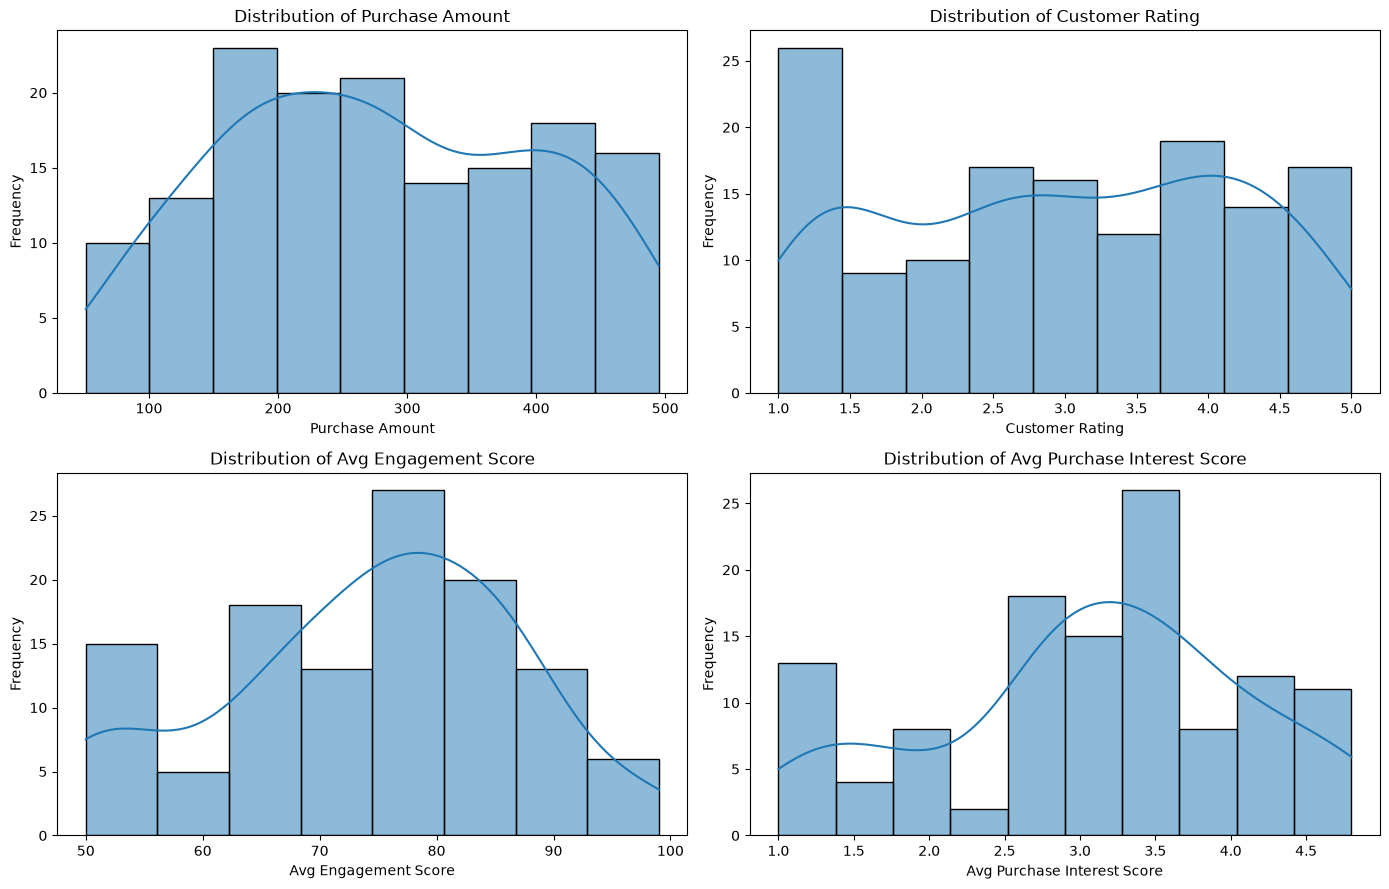

In [45]:
distribution_columns = [
    "purchase_amount",
    "customer_rating",
    "avg_engagement_score",
    "avg_purchase_interest_score"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for column, ax in zip(distribution_columns, axes.flatten()):
    sns.histplot(
        data=merged_data,
        x=column,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The histograms reveal different distribution patterns across the numerical features.

- Purchase amount: Values are spread across the range of 51 to 495, with many transactions concentrated between approximately 150 and 300.
- Customer rating: Ratings range from 1 to 5, with observations distributed across the scale and noticeable concentrations around 1 and 4.
- Average engagement score: Most available customer scores fall between approximately 65 and 90, with a higher concentration around 75 to 85.
- Average purchase-interest score: Values are concentrated mainly between approximately 2.5 and 4, although some customers have lower scores.

These distributions show variation in transaction amounts, customer ratings, and social media characteristics.

### Product Category Distribution

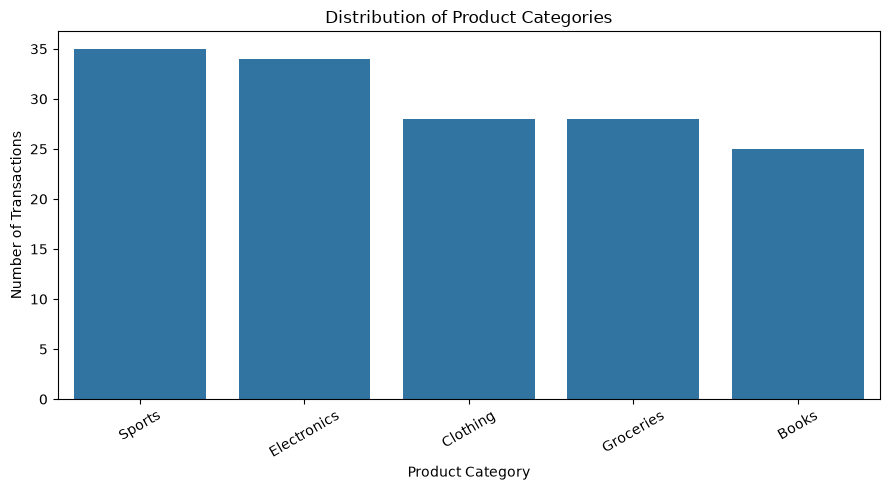

In [46]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=merged_data,
    x="product_category",
    order=merged_data["product_category"].value_counts().index
)

plt.title("Distribution of Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

The count plot shows the distribution of transactions across five product categories.

Sports has the highest number of transactions (35), followed by Electronics (34). Clothing and Groceries each have 28 transactions, while Books has the lowest count at 25.

The differences between the categories are relatively small, indicating that the target variable is reasonably balanced. No single category dominates the dataset.

### Outlier Detection Using Boxplots

I will use boxplots to help us identify potential outliers by displaying the median, quartiles, and observations outside the whiskers. This allows us to examine unusual values in important numerical features.

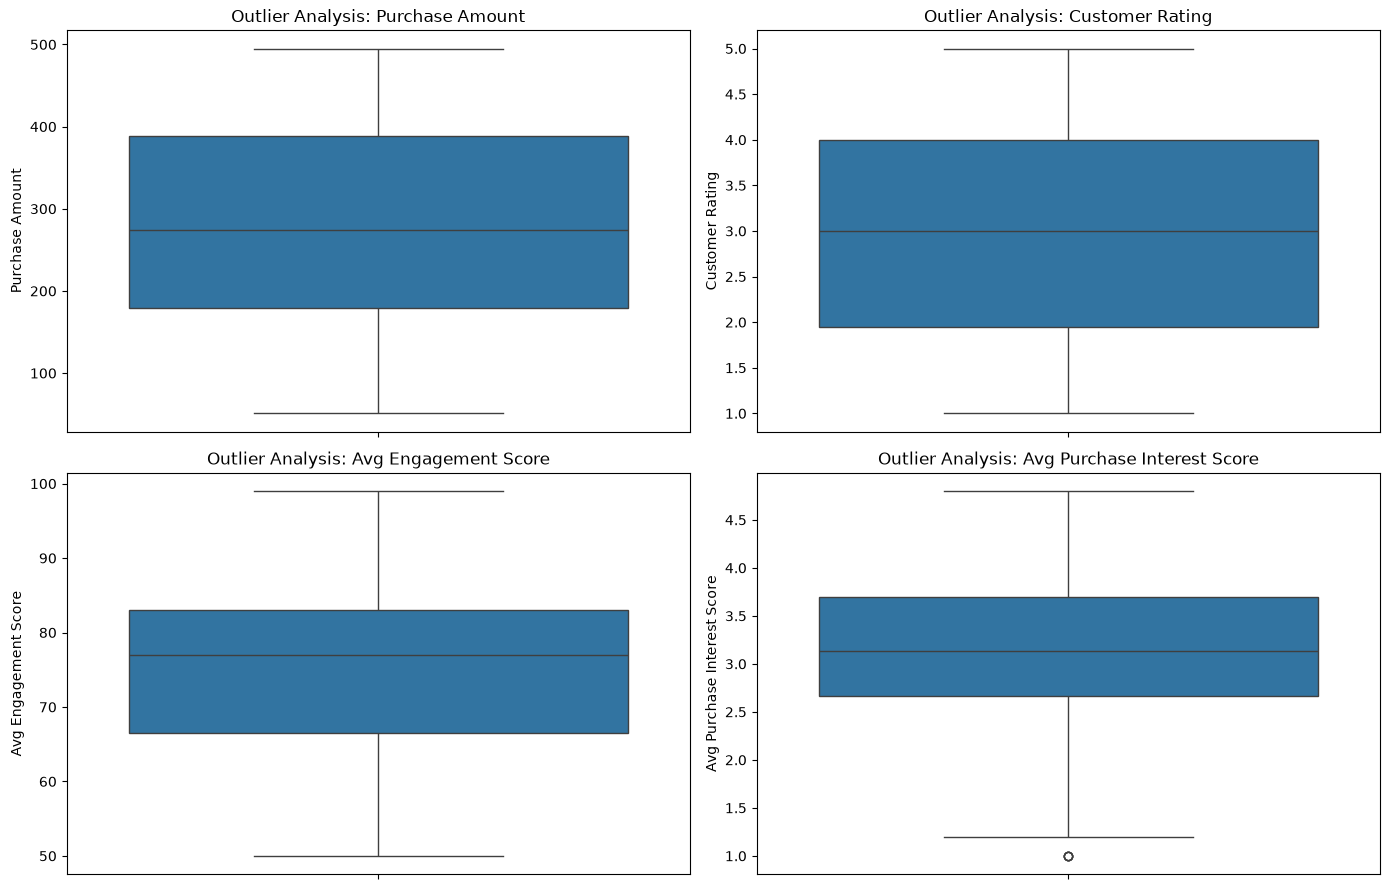

In [47]:
outlier_columns = [
    "purchase_amount",
    "customer_rating",
    "avg_engagement_score",
    "avg_purchase_interest_score"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for column, ax in zip(outlier_columns, axes.flatten()):
    sns.boxplot(
        data=merged_data,
        y=column,
        ax=ax
    )
    ax.set_title(f"Outlier Analysis: {column.replace('_', ' ').title()}")
    ax.set_ylabel(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

The boxplots were used to identify potential outliers in the numerical features.

Purchase amount, customer rating, and average engagement score show no visible observations beyond their whiskers.

Average purchase-interest score contains one potential low outlier around 1.0. This value is within the original scoring scale and may represent a genuine customer response rather than an error.

### Correlation Analysis

A correlation matrix measures the linear relationships between numerical variables. A heatmap provides a visual representation of these relationships, helping identify strongly related features and possible redundancy among variables.

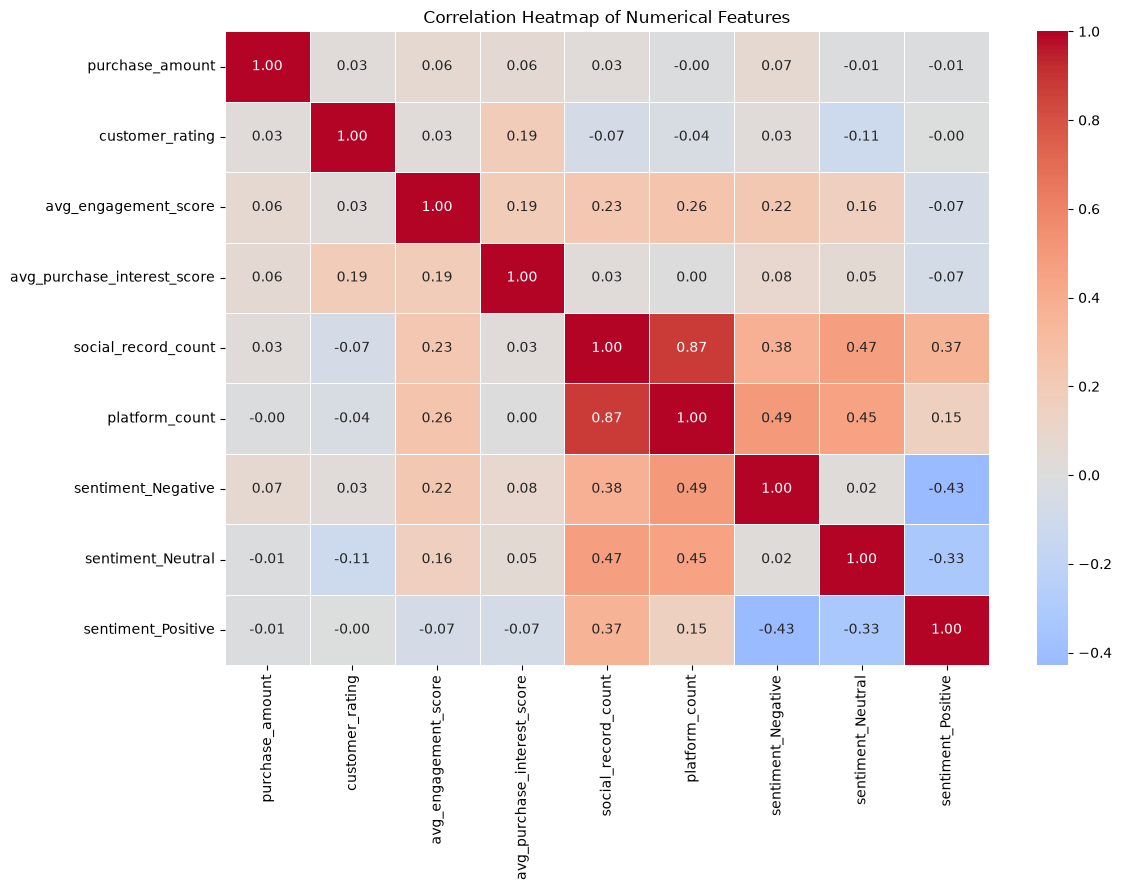

In [48]:
correlation_columns = [
    "purchase_amount",
    "customer_rating",
    "avg_engagement_score",
    "avg_purchase_interest_score",
    "social_record_count",
    "platform_count",
    "sentiment_Negative",
    "sentiment_Neutral",
    "sentiment_Positive"
]

correlation_matrix = merged_data[
    correlation_columns
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

The correlation heatmap shows the linear relationships among the numerical features.

The strongest positive relationship is between social_record_count and platform_count (0.87). This indicates that customers with more social media records tend to have a greater number of distinct platforms represented.

Sentiment_Negative and sentiment_Positive have a moderate negative correlation (-0.43), while average engagement score and platform_count have a weak positive correlation (0.26).

Most relationships involving purchase_amount and the social media scores are weak, suggesting limited linear association between these individual features.

The sentiment counts are derived from the same social media records, so some of their correlations reflect how the features were constructed.

The target variable, product_category, is not included in this heatmap because it is categorical. Additional analysis is therefore required to investigate relationships between numerical features and the target.

### Relationship Between Numerical Features and Product Categories

Boxplots for comparing numerical feature distributions across product categories. This helps us investigate whether customer characteristics and purchasing behavior differ between categories.

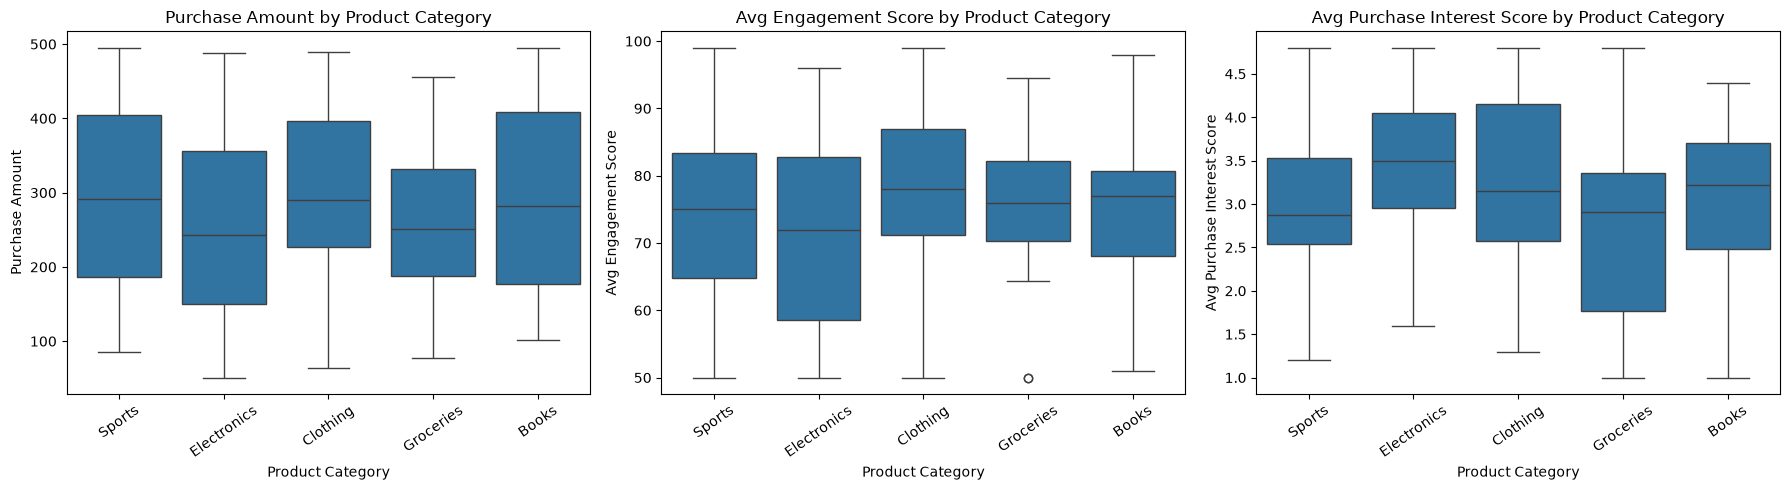

In [49]:
features_to_compare = [
    "purchase_amount",
    "avg_engagement_score",
    "avg_purchase_interest_score"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for column, ax in zip(features_to_compare, axes):
    sns.boxplot(
        data=merged_data,
        x="product_category",
        y=column,
        ax=ax
    )
    ax.set_title(
        f"{column.replace('_', ' ').title()} by Product Category"
    )
    ax.set_xlabel("Product Category")
    ax.set_ylabel(column.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

The boxplots compare purchase amount, average engagement score, and average purchase-interest score across the five product categories.

Sports and Clothing show higher median purchase amounts, while Books has a wider spread of purchase amounts. Clothing has the highest median engagement score, whereas Electronics shows greater variation in engagement.

Electronics has the highest median purchase-interest score, while Sports and Groceries have relatively lower medians.

Although some differences exist between categories, their distributions overlap considerably. This suggests that individual numerical features may not be sufficient to distinguish product categories on their own. Combining multiple features may provide more useful information for classification.

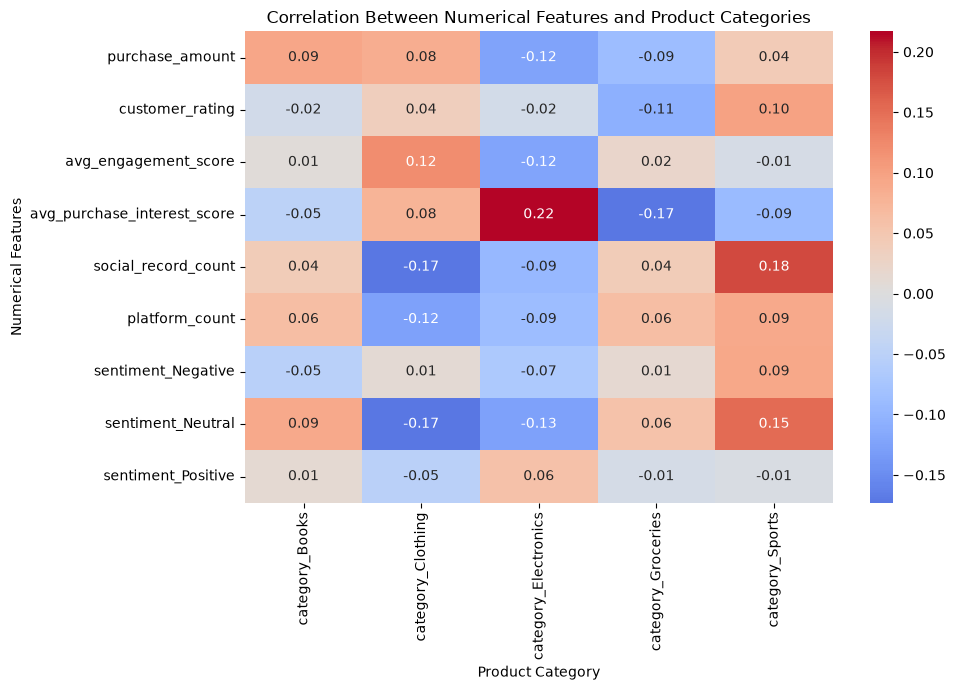

In [50]:
category_encoded = pd.get_dummies(
    merged_data["product_category"],
    prefix="category",
    dtype=int
)

target_correlation = pd.concat(
    [
        merged_data[correlation_columns],
        category_encoded
    ],
    axis=1
).corr()

category_relationships = target_correlation[
    category_encoded.columns
].loc[correlation_columns]

plt.figure(figsize=(10, 7))

sns.heatmap(
    category_relationships,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features and Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()

The heatmap examines the linear relationships between numerical features and the one-hot encoded product categories.

The strongest positive relationship is between average purchase-interest score and Electronics (0.22). Social record count has a positive relationship with Sports (0.18), while neutral sentiment also has a positive relationship with Sports (0.15).

Negative relationships include social record count with Clothing (-0.17) and average purchase-interest score with Groceries (-0.17).

However, all correlation values are relatively weak, indicating that no individual numerical feature has a strong linear relationship with a product category.

These findings suggest that product-category prediction may require combining several features rather than relying on a single feature. Correlation alone cannot determine which features will perform best in a classification model.

### 6.1 Feature Selection

In this step, we select the features that will be used to predict `product_category`. We exclude identifiers and information that would only become available after a purchase, while retaining relevant customer social-profile features.

In [51]:
feature_columns = [
    "avg_engagement_score",
    "avg_purchase_interest_score",
    "social_record_count",
    "platform_count",
    "sentiment_Negative",
    "sentiment_Neutral",
    "sentiment_Positive",
    "has_social_profile"
]

target_column = "product_category"

X = merged_data[feature_columns].copy()
y = merged_data[target_column].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("\nSelected features:")
print(X.columns.tolist())

Feature dataset shape: (150, 8)
Target dataset shape: (150,)

Selected features:
['avg_engagement_score', 'avg_purchase_interest_score', 'social_record_count', 'platform_count', 'sentiment_Negative', 'sentiment_Neutral', 'sentiment_Positive', 'has_social_profile']



The feature dataset contains 150 records and eight selected features, while the target dataset contains 150 corresponding product-category labels.

We retained social media engagement, purchase-interest, activity, sentiment, and profile-availability features because they provide information about customer interests and behaviour.

Transaction amounts, customer ratings, dates, and identifiers were excluded because they are either unavailable at the intended recommendation stage or do not represent meaningful predictive measurements.

This feature selection establishes the initial inputs for our product-category prediction model.

### 6.2 Handling Missing Values

In this step, we handle missing values in the selected features. We distinguish between customers without a matching social profile and missing values in the original transaction data.

In [52]:
# Identify customers without a matching social profile
no_social_profile = X["has_social_profile"] == 0

# Set record, platform, and sentiment counts to zero
count_columns = [
    "social_record_count",
    "platform_count",
    "sentiment_Negative",
    "sentiment_Neutral",
    "sentiment_Positive"
]

X.loc[no_social_profile, count_columns] = 0

# Inspect missing values after handling structural zeros
missing_features = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Percentage (%)": (X.isnull().mean() * 100).round(2)
})

print("Missing values in selected features:")
display(missing_features)

print("\nCustomers without social profiles:", no_social_profile.sum())
print("Missing customer ratings in original data:",
      merged_data["customer_rating"].isnull().sum())

Missing values in selected features:


,Missing Values,Percentage (%)
avg_engagement_score,33,22.0
avg_purchase_interest_score,33,22.0
social_record_count,0,0.0
platform_count,0,0.0
sentiment_Negative,0,0.0
sentiment_Neutral,0,0.0
sentiment_Positive,0,0.0
has_social_profile,0,0.0



Customers without social profiles: 33
Missing customer ratings in original data: 10



After handling records without matching social profiles, the count-based features and profile-availability indicator contain no missing values.

However, `avg_engagement_score` and `avg_purchase_interest_score` each contain 33 missing values (22%). These missing values represent customers for whom no matching social-profile information was found.

We retain these missing scores rather than replacing them with zero, since zero would incorrectly represent an actual measured score.

The remaining missing values will be handled during model preprocessing using statistics learned from the training data only.

### 6.3 Preparing Training, Validation, and Testing Datasets

In this step, we divide the dataset into three subsets: training, validation, and testing.

The training set will be used to fit the model, the validation set will support model selection and hyperparameter tuning, and the testing set will be reserved for final evaluation.

We keep transactions from the same customer in one subset to reduce the risk of customer information appearing across multiple subsets.

In [53]:
# Customer IDs are used for grouping, not as model features
groups = merged_data["customer_id_key"]

# First split: 80% development data and 20% testing data
splitter_1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

development_index, test_index = next(
    splitter_1.split(X, y, groups=groups)
)

X_development = X.iloc[development_index].copy()
X_test = X.iloc[test_index].copy()

y_development = y.iloc[development_index].copy()
y_test = y.iloc[test_index].copy()

groups_development = groups.iloc[development_index]

# Second split: divide development data into training and validation
splitter_2 = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

train_index, validation_index = next(
    splitter_2.split(
        X_development,
        y_development,
        groups=groups_development
    )
)

X_train = X_development.iloc[train_index].copy()
X_validation = X_development.iloc[validation_index].copy()

y_train = y_development.iloc[train_index].copy()
y_validation = y_development.iloc[validation_index].copy()

print("Training set:", X_train.shape)
print("Validation set:", X_validation.shape)
print("Testing set:", X_test.shape)

Training set: (89, 8)
Validation set: (30, 8)
Testing set: (31, 8)



The 150 transaction records were divided into three subsets: 89 training records (59.3%), 30 validation records (20.0%), and 31 testing records (20.7%).

The training set will be used to fit the model, the validation set will support model selection and hyperparameter tuning, and the testing set will be reserved for final evaluation.

The resulting distribution is approximately 60:20:20.

In [54]:
category_distribution = pd.DataFrame({
    "Training Count": y_train.value_counts(),
    "Validation Count": y_validation.value_counts(),
    "Testing Count": y_test.value_counts()
}).fillna(0).astype(int)

category_distribution["Training (%)"] = (
    y_train.value_counts(normalize=True) * 100
).round(2)

category_distribution["Validation (%)"] = (
    y_validation.value_counts(normalize=True) * 100
).round(2)

category_distribution["Testing (%)"] = (
    y_test.value_counts(normalize=True) * 100
).round(2)

display(category_distribution)

,Training Count,Validation Count,Testing Count,Training (%),Validation (%),Testing (%)
product_category,,,,,,
Books,15,5,5,16.85,16.67,16.13
Clothing,17,5,6,19.10,16.67,19.35
Electronics,20,7,7,22.47,23.33,22.58
Groceries,16,6,6,17.98,20.00,19.35
Sports,21,7,7,23.60,23.33,22.58


All five product categories are represented in the training, validation, and testing sets.

The proportions of the categories are relatively consistent across the three subsets. Electronics, for example, represents 22.47% of the training set, 23.33% of the validation set, and 22.58% of the testing set.

This indicates that the splitting process has maintained a reasonably balanced representation of the target variable across the subsets.

In [55]:
train_customers = set(groups_development.iloc[train_index])
validation_customers = set(groups_development.iloc[validation_index])
test_customers = set(groups.iloc[test_index])

print("Training customers:", len(train_customers))
print("Validation customers:", len(validation_customers))
print("Testing customers:", len(test_customers))

print("\nTraining and validation overlap:",
      len(train_customers & validation_customers))

print("Training and testing overlap:",
      len(train_customers & test_customers))

print("Validation and testing overlap:",
      len(validation_customers & test_customers))

Training customers: 43
Validation customers: 15
Testing customers: 17

Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0



The dataset contains 75 unique customers, distributed across the training, validation, and testing sets.

The overlap checks returned zero for all three comparisons, confirming that no customer appears in more than one subset.

This grouping reduces the risk of customer-level data leakage and provides a more reliable evaluation of how the model may perform on customers it has not encountered during training.

### 6.4 Handling Remaining Missing Values

In this step, we handle the remaining missing values in the social media engagement and purchase-interest features.

We use median imputation, fitting the imputer on the training data only. The same learned values are then applied to the validation and testing data to prevent data leakage.

In [56]:
imputation_columns = [
    "avg_engagement_score",
    "avg_purchase_interest_score"
]

print("Missing values before imputation:")
print("Training:", X_train[imputation_columns].isnull().sum().to_dict())
print("Validation:", X_validation[imputation_columns].isnull().sum().to_dict())
print("Testing:", X_test[imputation_columns].isnull().sum().to_dict())

Missing values before imputation:
Training: {'avg_engagement_score': 19, 'avg_purchase_interest_score': 19}
Validation: {'avg_engagement_score': 4, 'avg_purchase_interest_score': 4}
Testing: {'avg_engagement_score': 10, 'avg_purchase_interest_score': 10}


In [57]:
# Initialize the median imputer
imputer = SimpleImputer(strategy="median")

# Learn median values from training data and transform it
X_train_prepared = X_train.copy()
X_validation_prepared = X_validation.copy()
X_test_prepared = X_test.copy()

X_train_prepared[imputation_columns] = imputer.fit_transform(
    X_train[imputation_columns]
)

# Apply the same learned medians to validation and testing data
X_validation_prepared[imputation_columns] = imputer.transform(
    X_validation[imputation_columns]
)

X_test_prepared[imputation_columns] = imputer.transform(
    X_test[imputation_columns]
)

print("Training medians used for imputation:")
print(dict(zip(imputation_columns, imputer.statistics_)))

Training medians used for imputation:
{'avg_engagement_score': np.float64(76.33500000000001), 'avg_purchase_interest_score': np.float64(3.05)}


In [58]:
print("Missing values after imputation:")

print("\nTraining:")
print(X_train_prepared.isnull().sum())

print("\nValidation:")
print(X_validation_prepared.isnull().sum())

print("\nTesting:")
print(X_test_prepared.isnull().sum())

Missing values after imputation:

Training:
avg_engagement_score           0
avg_purchase_interest_score    0
social_record_count            0
platform_count                 0
sentiment_Negative             0
sentiment_Neutral              0
sentiment_Positive             0
has_social_profile             0
dtype: int64

Validation:
avg_engagement_score           0
avg_purchase_interest_score    0
social_record_count            0
platform_count                 0
sentiment_Negative             0
sentiment_Neutral              0
sentiment_Positive             0
has_social_profile             0
dtype: int64

Testing:
avg_engagement_score           0
avg_purchase_interest_score    0
social_record_count            0
platform_count                 0
sentiment_Negative             0
sentiment_Neutral              0
sentiment_Positive             0
has_social_profile             0
dtype: int64


In [59]:
print("Prepared dataset shapes:")
print("Training:", X_train_prepared.shape)
print("Validation:", X_validation_prepared.shape)
print("Testing:", X_test_prepared.shape)

print("\nFeature consistency:")
print(
    "All feature columns match:",
    list(X_train_prepared.columns)
    == list(X_validation_prepared.columns)
    == list(X_test_prepared.columns)
)

print("\nAll datasets contain numerical values:")
print("Training:", X_train_prepared.select_dtypes(include=np.number).shape)
print("Validation:", X_validation_prepared.select_dtypes(include=np.number).shape)
print("Testing:", X_test_prepared.select_dtypes(include=np.number).shape)

Prepared dataset shapes:
Training: (89, 8)
Validation: (30, 8)
Testing: (31, 8)

Feature consistency:
All feature columns match: True

All datasets contain numerical values:
Training: (89, 8)
Validation: (30, 8)
Testing: (31, 8)


In [60]:
datasets_ready = (
    not X_train_prepared.isnull().any().any()
    and not X_validation_prepared.isnull().any().any()
    and not X_test_prepared.isnull().any().any()
    and X_train_prepared.columns.equals(X_validation_prepared.columns)
    and X_train_prepared.columns.equals(X_test_prepared.columns)
)

print("Are all feature datasets ready for model training?", datasets_ready)

Are all feature datasets ready for model training? True



Before imputation, the training set contained 19 missing values in each of the two social media score features, the validation set contained 4 in each feature, and the testing set contained 10 in each feature.

We used median imputation, learning the median values from the training set only:
- Average engagement score: 76.335
- Average purchase-interest score: 3.05

The same median values were applied to the validation and testing sets to prevent data leakage.

After imputation, all three datasets contained zero missing values. Their original shapes were preserved: 89 training records, 30 validation records, and 31 testing records, each containing eight features.

All feature columns were consistent across the three datasets, and all selected features were numerical.

The final readiness check returned `True`, confirming that the prepared feature datasets are ready for the model training stage.

# Section 7: Model Training and Evaluation

In this section, we will develop and evaluate machine learning models to predict the product category a customer is likely to purchase.

We will begin by establishing a baseline, then train and compare different classification algorithms using the prepared training and validation datasets. Finally, we will use the testing dataset to evaluate the selected model's performance.

### 7.1 Selection of Classification Algorithms

We will experiment with different classification algorithms to identify suitable approaches for predicting product categories.

The experiments will include Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, K-Nearest Neighbors, and Gaussian Naive Bayes.

A Dummy Classifier will first establish a baseline for comparison. The models will be evaluated using accuracy, precision, recall, macro F1-score, loss and confusion matrices.

Model selection will be based primarily on validation performance, while the testing dataset will be reserved for the final evaluation.

### 7.2 Establishing a Baseline Model

We establish a baseline using a Dummy Classifier that always predicts the most frequent product category in the training data.

This provides a reference performance level that our machine learning models should aim to improve upon.

In [61]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train_prepared, y_train)

baseline_predictions = baseline_model.predict(X_validation_prepared)
baseline_probabilities = baseline_model.predict_proba(X_validation_prepared)

baseline_accuracy = accuracy_score(
    y_validation,
    baseline_predictions
)

baseline_f1 = f1_score(
    y_validation,
    baseline_predictions,
    average="macro"
)

baseline_loss = log_loss(
    y_validation,
    baseline_probabilities,
    labels=baseline_model.classes_
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Macro F1-score:", round(baseline_f1, 4))
print("Baseline Log Loss:", round(baseline_loss, 4))

Baseline Accuracy: 0.2333
Baseline Macro F1-score: 0.0757
Baseline Log Loss: 27.6335


These results establish a baseline for comparison. More advanced models should aim to achieve higher accuracy and macro F1-score, alongside lower log loss.

In [82]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", CalibratedClassifierCV(
            estimator=SVC(
                kernel="rbf",
                random_state=42
            ),
            method="sigmoid",
            cv=3
        ))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Gaussian Naive Bayes": GaussianNB()
}

In [84]:
results = []

# Include the baseline in our comparison
all_models = {
    "Dummy Baseline": baseline_model,
    **models
}

for model_name, model in all_models.items():

    # Train the model
    model.fit(X_train_prepared, y_train)

    # Predict using validation data
    predictions = model.predict(X_validation_prepared)

    # Get predicted probabilities for log loss
    probabilities = model.predict_proba(X_validation_prepared)

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_validation, predictions
        ),

        "Precision (Macro)": precision_score(
            y_validation, predictions,
            average="macro", zero_division=0
        ),

        "Recall (Macro)": recall_score(
            y_validation, predictions,
            average="macro", zero_division=0
        ),

        "F1-score (Macro)": f1_score(
            y_validation, predictions,
            average="macro", zero_division=0
        ),

        "Log Loss": log_loss(
            y_validation,
            probabilities,
            labels=model.classes_
        )
    })

results_df = pd.DataFrame(results)

# Sort by macro F1-score (our primary selection metric)
results_df = results_df.sort_values(
    by="F1-score (Macro)",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Log Loss
0,Logistic Regression,0.2333,0.2151,0.2210,0.2167,1.9134
1,K-Nearest Neighbors,0.2333,0.2143,0.2343,0.2108,12.7967
2,SVM,0.2667,0.1902,0.2333,0.1954,1.5614
3,Random Forest,0.2667,0.1857,0.2333,0.1953,4.1318
4,Gaussian Naive Bayes,0.2000,0.1779,0.2105,0.1785,2.9949
5,Decision Tree,0.1667,0.1600,0.1590,0.1568,24.3585
6,Dummy Baseline,0.2333,0.0467,0.2000,0.0757,27.6335


- **SVM** achieved the highest accuracy (26.67%) and the lowest log loss (1.5614).
- **Logistic Regression** achieved the highest macro F1-score (21.67%), making it the best model for balanced classification performance.
- **KNN** achieved a macro F1-score of 21.08%, close to Logistic Regression, but had a high log loss (12.7967).
- **Random Forest** achieved 26.67% accuracy but a lower macro F1-score (19.53%).
- **Decision Tree** performed worst among the trained models, with 16.67% accuracy and a macro F1-score of 15.68%.
- All trained models achieved better macro F1-scores than the Dummy Baseline (7.57%).

Overall, Logistic Regression is the strongest candidate based on macro F1-score, while SVM performed best in accuracy and log loss. However, all models showed low predictive performance, indicating that further improvements are needed.

The Extra Trees model achieved 20% validation accuracy and a macro F1-score of 0.1663. The confusion matrix shows that the model correctly classified only 6 out of 30 transactions.

Electronics and Groceries had the strongest category-level F1-scores, at 0.33 and 0.31 respectively. However, the model failed to correctly classify any Books or Clothing transactions. It also showed a tendency to predict Sports for transactions belonging to other categories.

These results indicate that Extra Trees has limited ability to distinguish between the five product categories using the available features. Therefore, it cannot yet be considered a reliable final prediction model.

### 7.4 Model Optimization and Comparison

After evaluating the initial models, we apply hyperparameter optimization to the six trainable classifiers. RandomizedSearchCV explores different hyperparameter configurations using three-fold StratifiedGroupKFold cross-validation.

Macro F1-score is used as the primary optimization metric because the task involves predicting five product categories. Accuracy and log loss are also recorded during validation to provide a broader performance comparison.

In [97]:
model_pipelines = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(random_state=42))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", CalibratedClassifierCV(
            estimator=SVC(kernel="rbf", random_state=42),
            method="sigmoid",
            cv=3
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

In [98]:
parameter_distributions = {
    "Logistic Regression": {
        "classifier__C": loguniform(1e-3, 1e2),
        "classifier__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 3, 5, 10, 15],
        "classifier__min_samples_split": randint(2, 10),
        "classifier__min_samples_leaf": randint(1, 6),
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": randint(100, 501),
        "classifier__max_depth": [None, 3, 5, 10, 15],
        "classifier__min_samples_split": randint(2, 10),
        "classifier__min_samples_leaf": randint(1, 5),
        "classifier__class_weight": [None, "balanced"]
    },

    "SVM": {
        "classifier__estimator__C": loguniform(1e-2, 1e2),
        "classifier__estimator__gamma": loguniform(1e-4, 1e0)
    },

    "K-Nearest Neighbors": {
        "classifier__n_neighbors": randint(3, 16),
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },

    "Gaussian Naive Bayes": {
        "classifier__var_smoothing": loguniform(1e-12, 1e-7)
    }
}

In [100]:

optimized_models = {}
optimization_results = []

scoring_metrics = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "neg_log_loss": "neg_log_loss"
}

for name, pipeline in model_pipelines.items():

    print(f"Optimizing {name}...")

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_distributions[name],
        n_iter=15,
        scoring=scoring_metrics,
        refit="f1_macro",
        cv=group_cv,
        random_state=42,
        n_jobs=-1,
        return_train_score=True
    )

    search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    optimized_models[name] = search.best_estimator_

    best_index = search.best_index_

    optimization_results.append({
        "Model": name,
        "Best CV Accuracy": search.cv_results_["mean_test_accuracy"][best_index],
        "Best CV Macro F1": search.cv_results_["mean_test_f1_macro"][best_index],
        "Best CV Log Loss": -search.cv_results_["mean_test_neg_log_loss"][best_index],
        "Best Parameters": search.best_params_
    })

    print(f"Best CV Accuracy: {optimization_results[-1]['Best CV Accuracy']:.4f}")
    print(f"Best CV Macro F1: {optimization_results[-1]['Best CV Macro F1']:.4f}")
    print(f"Best CV Log Loss: {optimization_results[-1]['Best CV Log Loss']:.4f}")
    print("-" * 50)

optimization_results_df = pd.DataFrame(optimization_results)

display(
    optimization_results_df.sort_values(
        by="Best CV Macro F1",
        ascending=False
    )
)


Optimizing Logistic Regression...
Best CV Accuracy: 0.2019
Best CV Macro F1: 0.1836
Best CV Log Loss: 1.7964
--------------------------------------------------
Optimizing Decision Tree...
Best CV Accuracy: 0.2123
Best CV Macro F1: 0.2059
Best CV Log Loss: 17.2603
--------------------------------------------------
Optimizing Random Forest...
Best CV Accuracy: 0.1785
Best CV Macro F1: 0.1770
Best CV Log Loss: 1.9484
--------------------------------------------------
Optimizing SVM...
Best CV Accuracy: 0.2464
Best CV Macro F1: 0.2211
Best CV Log Loss: 1.6251
--------------------------------------------------
Optimizing K-Nearest Neighbors...
Best CV Accuracy: 0.1908
Best CV Macro F1: 0.1695
Best CV Log Loss: 11.1621
--------------------------------------------------
Optimizing Gaussian Naive Bayes...
Best CV Accuracy: 0.1567
Best CV Macro F1: 0.1298
Best CV Log Loss: 4.3776
--------------------------------------------------


,Model,Best CV Accuracy,Best CV Macro F1,Best CV Log Loss,Best Parameters
3,SVM,0.246360,0.221060,1.625061,{'classifier__estimator__C': 2.537815508265665...
1,Decision Tree,0.212261,0.205873,17.260254,"{'classifier__class_weight': 'balanced', 'clas..."
0,Logistic Regression,0.201916,0.183562,1.796369,"{'classifier__C': 0.4206039057901998, 'classif..."
2,Random Forest,0.178544,0.176951,1.948365,"{'classifier__class_weight': 'balanced', 'clas..."
4,K-Nearest Neighbors,0.190805,0.169451,11.162111,"{'classifier__n_neighbors': 6, 'classifier__p'..."
5,Gaussian Naive Bayes,0.156705,0.129763,4.377624,{'classifier__var_smoothing': 7.45934328572656...



The six models were optimized using RandomizedSearchCV with 3-fold StratifiedGroupKFold cross-validation. Each model was evaluated using accuracy, macro F1-score, and log loss. Macro F1-score was used to select the best parameter configuration, while the other metrics provided additional performance information.

**Key observations:**

- **SVM** achieved the best results across all three metrics, with an accuracy of 0.2464, macro F1-score of 0.2211, and log loss of 1.6251. It was the strongest model during cross-validation.
- **Decision Tree** ranked second in macro F1-score (0.2059) and accuracy (0.2123). However, its log loss of 17.2603 indicates very poor probability estimates.
- **Logistic Regression** achieved a macro F1-score of 0.1836 and log loss of 1.7964, making it a reasonable alternative, although its overall performance was below SVM.
- **Random Forest** and **K-Nearest Neighbors** showed relatively weak macro F1-scores of 0.1770 and 0.1695, respectively.
- **Gaussian Naive Bayes** recorded the lowest accuracy (0.1567) and macro F1-score (0.1298).

**Overall interpretation:**

SVM was the strongest candidate based on cross-validation because it achieved the highest accuracy and macro F1-score, together with the lowest log loss. However, the scores were generally low, indicating that the models still have difficulty predicting product categories reliably.

These results represent cross-validation performance on the training data. Further evaluation on the separate validation set is necessary before selecting the final model.


In [101]:
validation_results = []

for name, model in optimized_models.items():

    # Predict categories
    y_pred = model.predict(X_validation)

    # Predict probabilities
    y_proba = model.predict_proba(X_validation)

    validation_results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_validation, y_pred),
        "Validation Macro F1": f1_score(
            y_validation, y_pred, average="macro", zero_division=0
        ),
        "Validation Log Loss": log_loss(
            y_validation, y_proba, labels=model.classes_
        )
    })

optimized_validation_df = pd.DataFrame(validation_results)

display(
    optimized_validation_df.sort_values(
        by="Validation Macro F1",
        ascending=False
    ).round(4)
)


,Model,Validation Accuracy,Validation Macro F1,Validation Log Loss
5,Gaussian Naive Bayes,0.2000,0.1785,2.9949
3,SVM,0.2667,0.1568,1.5690
1,Decision Tree,0.1667,0.1531,23.2336
2,Random Forest,0.2000,0.1531,1.9140
0,Logistic Regression,0.1667,0.1514,1.8323
4,K-Nearest Neighbors,0.1667,0.1475,9.5010


After optimizing the six models, we evaluated their best configurations on the separate validation dataset. This allowed us to examine how well the optimized models performed on data that was not used during their training or parameter search.

**Key observations:**

- **Gaussian Naive Bayes** achieved the highest macro F1-score of 0.1785, with an accuracy of 0.2000. Although it ranked last during cross-validation, it performed best in macro F1-score on the validation set.
- **SVM** achieved the highest validation accuracy of 0.2667 and the lowest log loss of 1.5690. However, its macro F1-score was only 0.1568, suggesting that its predictions were not balanced across the product categories.
- **Decision Tree** achieved a macro F1-score of 0.1531 and accuracy of 0.1667. Its very high log loss of 23.2336 indicates poor probability estimates.
- **Random Forest** achieved an accuracy of 0.2000 and macro F1-score of 0.1531, with a log loss of 1.9140.
- **Logistic Regression** recorded an accuracy of 0.1667, macro F1-score of 0.1514, and log loss of 1.8323.
- **K-Nearest Neighbors** recorded the lowest macro F1-score among the optimized models (0.1475), together with a log loss of 9.5010.

**Overall:**

The validation results differ from the cross-validation results. SVM maintained the highest accuracy and lowest log loss, but Gaussian Naive Bayes achieved the highest macro F1-score.

This difference suggests that the models may perform inconsistently across different data samples. No single model performed best across all three validation metrics.

At this stage, SVM is strongest in overall accuracy and probability performance, while Gaussian Naive Bayes is strongest in macro F1-score. We should examine their class-level performance and compare optimized models with their original untuned versions before selecting the final model.


In [104]:
class_results = []

for name, model in optimized_models.items():

    y_pred = model.predict(X_validation)

    report = classification_report(
        y_validation,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    for category in model.classes_:
        class_results.append({
            "Model": name,
            "Category": category,
            "Precision": report[category]["precision"],
            "Recall": report[category]["recall"],
            "F1-score": report[category]["f1-score"],
            "Support": report[category]["support"]
        })

class_results_df = pd.DataFrame(class_results)

display(
    class_results_df.round(3)
)


,Model,Category,Precision,Recall,F1-score,Support
0,Logistic Regression,Books,0.250,0.200,0.222,5.0
1,Logistic Regression,Clothing,0.000,0.000,0.000,5.0
2,Logistic Regression,Electronics,0.300,0.429,0.353,7.0
3,Logistic Regression,Groceries,0.200,0.167,0.182,6.0
4,Logistic Regression,Sports,0.000,0.000,0.000,7.0
5,Decision Tree,Books,0.167,0.200,0.182,5.0
6,Decision Tree,Clothing,0.000,0.000,0.000,5.0
7,Decision Tree,Electronics,0.200,0.286,0.235,7.0
8,Decision Tree,Groceries,0.200,0.167,0.182,6.0
9,Decision Tree,Sports,0.200,0.143,0.167,7.0



The classification reports were examined to understand how each optimized model predicts the five product categories: Books, Clothing, Electronics, Groceries and Sports.

**Key observations:**

- **Logistic Regression:** Electronics achieved the highest F1-score (0.353), while Clothing and Sports had zero F1-scores.
- **Decision Tree:** Electronics performed best with an F1-score of 0.235. Clothing had a zero F1-score.
- **Random Forest:** Electronics achieved the highest F1-score (0.375), while Books and Clothing had zero F1-scores.
- **SVM:** Electronics achieved an F1-score of 0.462, while Sports achieved an F1-score of 0.323 and recall of 0.714. However, Books, Clothing and Groceries had zero F1-scores.
- **K-Nearest Neighbors:** Electronics performed best with an F1-score of 0.364, while Books and Clothing had zero F1-scores.
- **Gaussian Naive Bayes:** Clothing achieved the highest F1-score (0.375), with a recall of 0.600. Books had a zero F1-score.

**Overall findings:**

Electronics was the strongest-performing category for most models. SVM showed particularly strong recall for Sports, while Gaussian Naive Bayes performed best for Clothing.

Books was the most challenging category because none of the six models correctly classified any Books transactions. Clothing was also difficult for most models.

Overall, the results show that the models struggle to classify all five product categories consistently. The highest-performing model on an individual category is not necessarily the best overall model.

These findings will help us examine the confusion matrices and compare the optimized models with their original untuned versions.


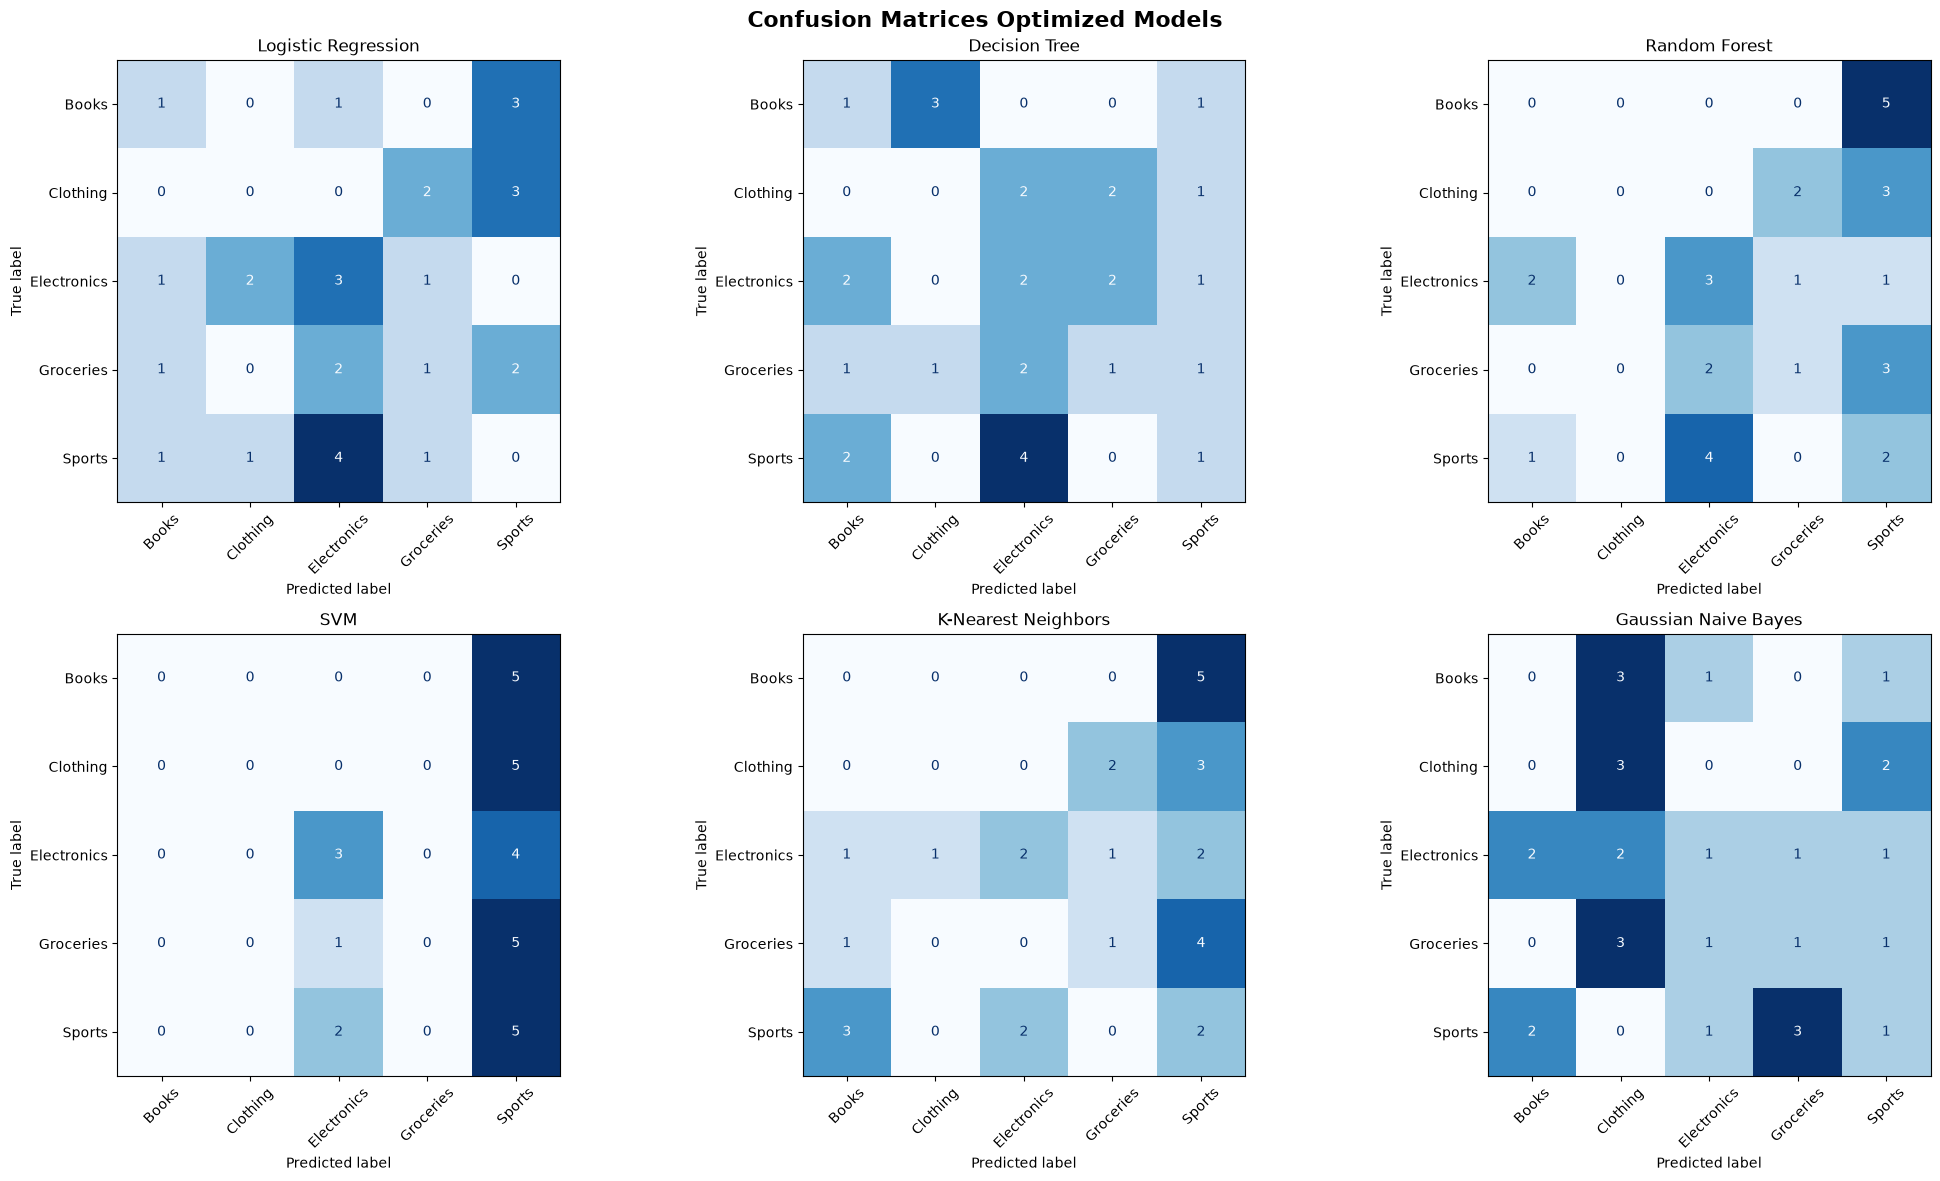

In [108]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))

axes = axes.flatten()

for ax, (name, model) in zip(axes, optimized_models.items()):

    y_pred = model.predict(X_validation)

    ConfusionMatrixDisplay.from_predictions(
        y_validation,
        y_pred,
        labels=model.classes_,
        display_labels=model.classes_,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name, fontsize=12)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Confusion Matrices Optimized Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()




The confusion matrices examined the actual and predicted product categories for each optimized model. 

**Key observations:**

- **Logistic Regression:** Correctly classified 5 out of 30 transactions (16.67%). It performed best on Electronics, correctly identifying 3 transactions, but failed to identify Clothing and Sports correctly.
- **Decision Tree:** Correctly classified 5 out of 30 transactions (16.67%). It correctly identified 2 Electronics transactions but failed to correctly identify Clothing.
- **Random Forest:** Correctly classified 6 out of 30 transactions (20.00%). It correctly identified 3 Electronics and 2 Sports transactions but failed to identify Books and Clothing correctly.
- **SVM:** Correctly classified 8 out of 30 transactions (26.67%). It correctly identified 3 Electronics and 5 Sports transactions. However, it predicted almost exclusively Electronics and Sports, failing to predict Books, Clothing and Groceries.
- **K-Nearest Neighbors:** Correctly classified 5 out of 30 transactions (16.67%). It correctly identified some Electronics, Groceries and Sports transactions but failed to identify Books and Clothing correctly.
- **Gaussian Naive Bayes:** Correctly classified 6 out of 30 transactions (20.00%). It performed best on Clothing, correctly identifying 3 transactions, but failed to identify Books correctly.


The confusion matrices reveal that the models struggle to distinguish between all five product categories. Several models favor particular categories, resulting in frequent misclassification of other categories.

SVM achieved the highest number of correct predictions based on the supplied matrices, but its predictions were heavily concentrated in Electronics and Sports. Gaussian Naive Bayes showed better recognition of Clothing, while Random Forest performed relatively better on Electronics.

These results demonstrate why accuracy alone is insufficient for evaluating the models. Class-level precision, recall, F1-score and confusion matrices are also important when assessing classification performance.

The findings will be considered alongside cross-validation and validation metrics when comparing optimized and untuned models.


### 7.5 Comparison of Models Before and After Optimization

The initial and optimized validation results are brought together to examine the effect of hyperparameter optimization.

By comparing the results, we can identify which models improved, which performed worse, and whether optimization produced meaningful changes.

Macro F1-score remains our primary selection metric, while accuracy and log loss provide additional information about classification performance and predicted probabilities.

In [116]:
# Prepare initial results, excluding the Dummy Baseline
initial_comparison = results_df[
    results_df["Model"] != "Dummy Baseline"
].copy()

initial_comparison["Version"] = "Untuned"

initial_comparison = initial_comparison.rename(columns={
    "Accuracy": "Validation Accuracy",
    "F1-score (Macro)": "Validation Macro F1",
    "Log Loss": "Validation Log Loss"
})

# Prepare optimized results
optimized_comparison = optimized_validation_df.copy()
optimized_comparison["Version"] = "Optimized"

# Combine both result tables
combined_results = pd.concat(
    [
        initial_comparison[
            ["Model", "Version", "Validation Accuracy",
             "Validation Macro F1", "Validation Log Loss"]
        ],
        optimized_comparison[
            ["Model", "Version", "Validation Accuracy",
             "Validation Macro F1", "Validation Log Loss"]
        ]
    ],
    ignore_index=True
)

# Display models ranked by validation Macro F1
combined_results = combined_results.sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

display(combined_results.round(4))

,Model,Version,Validation Accuracy,Validation Macro F1,Validation Log Loss
0,Logistic Regression,Untuned,0.2333,0.2167,1.9134
1,K-Nearest Neighbors,Untuned,0.2333,0.2108,12.7967
2,SVM,Untuned,0.2667,0.1954,1.5614
3,Random Forest,Untuned,0.2667,0.1953,4.1318
4,Gaussian Naive Bayes,Untuned,0.2000,0.1785,2.9949
5,Gaussian Naive Bayes,Optimized,0.2000,0.1785,2.9949
6,SVM,Optimized,0.2667,0.1568,1.5690
7,Decision Tree,Untuned,0.1667,0.1568,24.3585
8,Decision Tree,Optimized,0.1667,0.1531,23.2336
9,Random Forest,Optimized,0.2000,0.1531,1.9140


### 7.6 Hyperparameter Tuning

After comparing the initial models, Logistic Regression emerged as a promising candidate because it achieved the highest validation Macro F1-score of 0.2167.

We evaluate different combinations of these parameters using the training dataset and compare their predictions on the validation dataset using Macro F1-score.

Macro F1 is selected as the optimization metric because it evaluates performance across all five product categories, giving each category equal importance regardless of its number of observations.

In [132]:

parameter_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs"]
    }
}

models_to_tune = [
    "Logistic Regression",
]

tuning_results = []
best_tuned_models = {}

for model_name in models_to_tune:

    best_score = -1
    best_model = None
    best_parameters = None

    for parameters in ParameterGrid(parameter_grids[model_name]):
        candidate_model = clone(models[model_name])
        candidate_model.set_params(**parameters)

        candidate_model.fit(X_train_prepared, y_train)

        # Predict on validation data
        predictions = candidate_model.predict(X_validation_prepared)

        probabilities = candidate_model.predict_proba(
            X_validation_prepared
        )

        # Evaluate the current configuration
        accuracy = accuracy_score(y_validation, predictions)

        macro_f1 = f1_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0
        )

        loss = log_loss(
            y_validation,
            probabilities,
            labels=candidate_model.classes_
        )

        # Select the configuration with the highest Macro F1
        if macro_f1 > best_score:
            best_score = macro_f1
            best_model = candidate_model
            best_parameters = parameters

    # Store the selected tuned model
    best_tuned_models[model_name] = best_model

    # Record the selected configuration's metrics
    best_predictions = best_model.predict(X_validation_prepared)
    best_probabilities = best_model.predict_proba(X_validation_prepared)

    tuning_results.append({
        "Model": model_name,
        "Best Validation Accuracy": accuracy_score(
            y_validation, best_predictions
        ),
        "Best Validation Macro F1": f1_score(
            y_validation,
            best_predictions,
            average="macro",
            zero_division=0
        ),
        "Best Validation Log Loss": log_loss(
            y_validation,
            best_probabilities,
            labels=best_model.classes_
        ),
        "Best Parameters": best_parameters
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df.round(4))


,Model,Best Validation Accuracy,Best Validation Macro F1,Best Validation Log Loss,Best Parameters
0,Logistic Regression,0.2333,0.2183,2.158,"{'classifier__C': 10, 'classifier__solver': 'l..."



The initial Logistic Regression model achieved a validation Macro F1-score of 0.2167. After testing different hyperparameter combinations, the best configuration used `C = 10` and the `lbfgs` solver, achieving a Macro F1-score of 0.2183.

This represents an improvement of 0.0016 over the initial model.

Although the improvement is small, the tuned configuration achieved a higher validation Macro F1-score than the initial configuration. Therefore, we select the tuned Logistic Regression model as our final candidate.

It is important to recognize that this improvement does not establish that the model has strong predictive performance. It only indicates that the selected configuration performed slightly better on the validation data.

### 7.7 Preparing the Final Model

After selecting the tuned Logistic Regression configuration, we prepare the final model for testing.

We combine the training and validation datasets to provide the selected model with more observations during its final fitting process.

The preprocessing pipeline includes median imputation and feature scaling. These transformations are fitted using the combined development dataset, ensuring that the test data does not influence preprocessing or model training.

The selected hyperparameters are retained when rebuilding the Logistic Regression classifier.

The resulting pipeline is then evaluated using the reserved testing dataset.

In [133]:
# Combine training and validation data
X_development_final = pd.concat(
    [X_train, X_validation],
    axis=0
)

y_development_final = pd.concat(
    [y_train, y_validation],
    axis=0
)

# Retrieve the best tuned Logistic Regression parameters
best_lr_parameters = (
    best_tuned_models["Logistic Regression"]
    .named_steps["classifier"]
    .get_params()
)

# Build the complete preprocessing and prediction pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(**best_lr_parameters))
])

# Fit using training + validation data
final_model.fit(X_development_final, y_development_final)

print("Final development dataset:", X_development_final.shape)
print("Final model trained successfully.")

Final development dataset: (119, 8)
Final model trained successfully.


### 7.8 Final Model Evaluation
We evaluate the final model using the testing dataset, which was not used during model selection, hyperparameter tuning, or final model fitting.

We examine accuracy, precision, recall, macro F1-score, and the confusion matrix to assess how well the model predicts the five product categories.

In [134]:
# Predict on the untouched test set
y_test_predictions = final_model.predict(X_test)

# Calculate final metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_predictions),
    "Precision (Macro)": precision_score(
        y_test, y_test_predictions,
        average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_test, y_test_predictions,
        average="macro", zero_division=0
    ),
    "F1-score (Macro)": f1_score(
        y_test, y_test_predictions,
        average="macro", zero_division=0
    )
}

final_metrics_df = pd.DataFrame(
    [final_metrics],
    index=["Final Logistic Regression"]
)

display(final_metrics_df.round(4))

,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
Final Logistic Regression,0.1935,0.15,0.1714,0.1423


In [140]:
print(
    classification_report(
        y_test,
        y_test_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.00      0.00      0.00         6
 Electronics       0.25      0.57      0.35         7
   Groceries       0.00      0.00      0.00         6
      Sports       0.50      0.29      0.36         7

    accuracy                           0.19        31
   macro avg       0.15      0.17      0.14        31
weighted avg       0.17      0.19      0.16        31



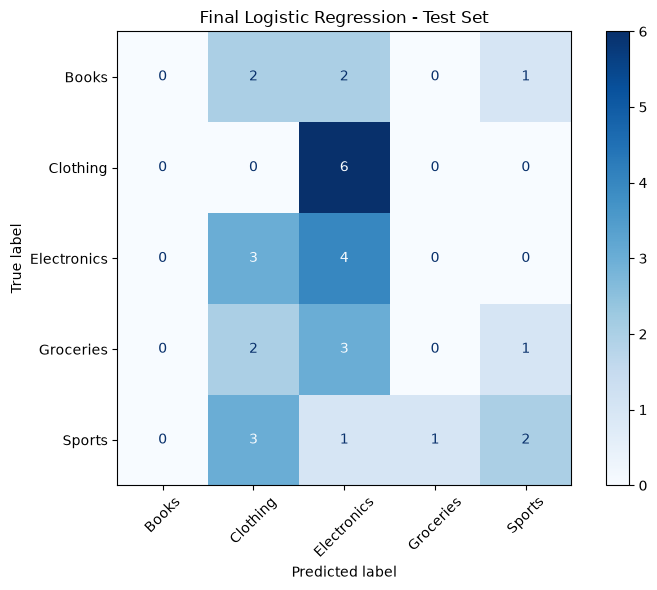

In [141]:
labels = sorted(y_train.unique())

cm = confusion_matrix(
    y_test,
    y_test_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.title("Final Logistic Regression - Test Set")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusion

The final tuned Logistic Regression model achieved an accuracy of 0.1935 and a Macro F1-score of 0.1423 on the testing dataset.

These results indicate that the model has limited ability to predict product categories using the available social media features.

Although hyperparameter tuning produced a small improvement in validation Macro F1-score, the final test results show that the improvement did not translate into strong generalization to unseen customers.

The classification results also suggest that the model does not perform consistently across all five product categories. This indicates that the selected social media features may not contain sufficient information to distinguish between the different product categories.

Several factors may contribute to this performance:

- The dataset contains only 150 transaction records, limiting the information available for model learning.
- The social media and transaction datasets were matched using an assumed customer ID relationship, which may affect the reliability of the merged data.
- The selected features have weak relationships with product category.
- The small number of customers in the testing dataset makes the evaluation results sensitive to individual predictions.

Overall, the experiment demonstrates that hyperparameter tuning can improve a model's validation performance slightly, but tuning alone cannot overcome limitations in the available data and features.

### 7.9 Saving the Final Model
We save the trained preprocessing and classification pipeline together with its required feature names and target information.

This allows the model to be reused by other components of the project without repeating the training process.

In [135]:
model_artifact = {
    "model": final_model,
    "feature_columns": feature_columns,
    "target_column": target_column,
    "classes": final_model.named_steps["classifier"].classes_.tolist(),
    "model_name": "Tuned Logistic Regression",
    "imputation_strategy": "median",
    "scaling": "StandardScaler"
}

joblib.dump(
    model_artifact,
    "../models/product_category_model.joblib"
)

print("Model saved successfully as product_category_model.joblib")

Model saved successfully as product_category_model.joblib


In [136]:
loaded_artifact = joblib.load("../models/product_category_model.joblib")

loaded_model = loaded_artifact["model"]

# Predict using the reloaded model
loaded_predictions = loaded_model.predict(X_test)

print("Model loaded successfully.")
print(
    "Predictions from loaded model match:",
    np.array_equal(loaded_predictions, y_test_predictions)
)

Model loaded successfully.
Predictions from loaded model match: True


In [137]:
def predict_product_category(customer_features, artifact):
    """
    Predict a product category from one customer's social-profile features.

    customer_features: dictionary containing the required eight features.
    artifact: loaded model artifact.
    """

    required_features = artifact["feature_columns"]

    input_data = pd.DataFrame(
        [customer_features],
        columns=required_features
    )

    prediction = artifact["model"].predict(input_data)[0]

    probabilities = artifact["model"].predict_proba(input_data)[0]

    probability_by_category = dict(
        zip(artifact["classes"], probabilities)
    )

    return {
        "predicted_category": prediction,
        "category_probabilities": probability_by_category
    }

In [138]:
example_customer = {
    "avg_engagement_score": 76.0,
    "avg_purchase_interest_score": 3.5,
    "social_record_count": 2,
    "platform_count": 2,
    "sentiment_Negative": 0,
    "sentiment_Neutral": 1,
    "sentiment_Positive": 1,
    "has_social_profile": 1
}

In [139]:
prediction_result = predict_product_category(
    example_customer,
    loaded_artifact
)

print(prediction_result)

{'predicted_category': 'Books', 'category_probabilities': {'Books': np.float64(0.2576653598558415), 'Clothing': np.float64(0.18586072543355342), 'Electronics': np.float64(0.22434074599699083), 'Groceries': np.float64(0.16964262870108934), 'Sports': np.float64(0.16249054001252491)}}
